In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ppghr.data import PROJECT_DIR

summary = json.load(open(PROJECT_DIR / "results" / "step9_summary.json"))
pd.DataFrame({name: {"MAE (bpm)": r["mae"], "within 5 bpm (%)": r["within_5_bpm_percent"]}
              for name, r in summary.items()}).T

,MAE (bpm),within 5 bpm (%)
CNN,6.02,73.5
"CNN, snapped",6.21,72.4
Step 8 booster,7.54,61.5
"CNN + booster average, snapped",6.53,65.5


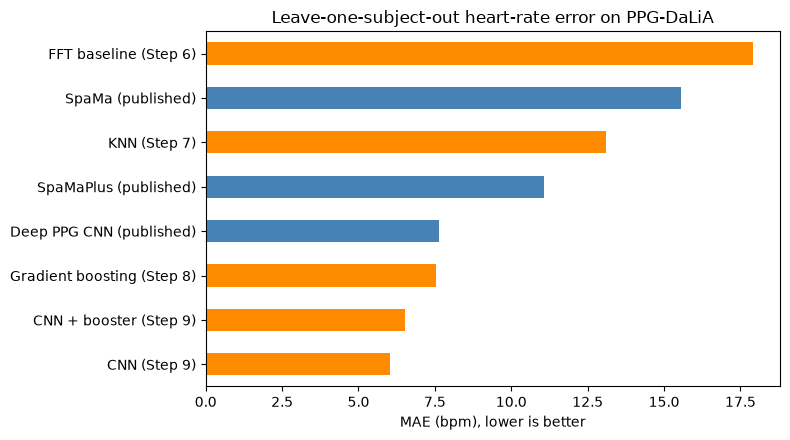

In [2]:
scores = pd.Series({
    "FFT baseline (Step 6)": 17.9,
    "SpaMa (published)": 15.56,
    "KNN (Step 7)": 13.1,
    "SpaMaPlus (published)": 11.06,
    "Deep PPG CNN (published)": 7.65,
    "Gradient boosting (Step 8)": summary["Step 8 booster"]["mae"],
    "CNN (Step 9)": summary["CNN"]["mae"],
    "CNN + booster (Step 9)": summary["CNN + booster average, snapped"]["mae"],
}).sort_values()
colors = ["darkorange" if "Step" in name else "steelblue" for name in scores.index]
scores.plot.barh(figsize=(8, 4.5), color=colors)
plt.xlabel("MAE (bpm), lower is better")
plt.title("Leave-one-subject-out heart-rate error on PPG-DaLiA")
plt.tight_layout()
plt.show()

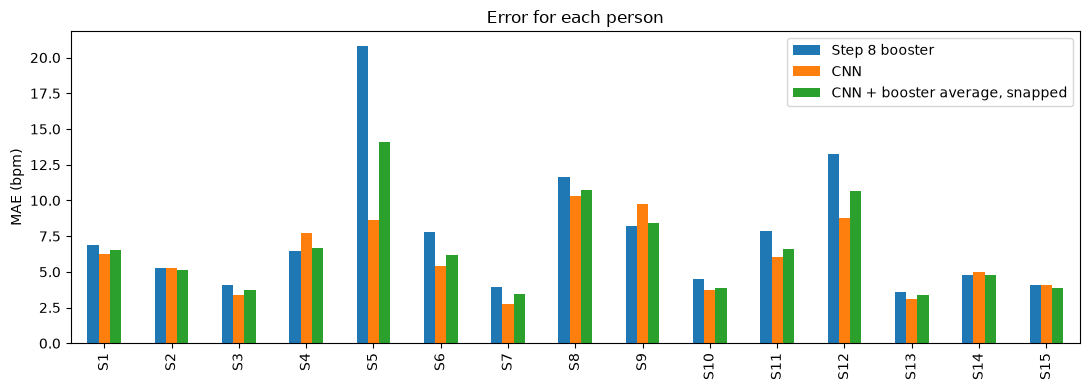

,CNN,"CNN, snapped",Step 8 booster,"CNN + booster average, snapped"
S1,6.2,6.4,6.9,6.5
S2,5.3,5.6,5.2,5.2
S3,3.4,3.6,4.1,3.7
S4,7.8,8.2,6.5,6.7
S5,8.6,8.6,20.8,14.1
S6,5.4,5.6,7.8,6.2
S7,2.7,2.9,3.9,3.4
S8,10.3,10.5,11.6,10.7
S9,9.8,10.2,8.2,8.4
S10,3.7,3.8,4.5,3.8


In [3]:
per_subject = pd.DataFrame({name: r["per_subject"] for name, r in summary.items()})
per_subject[["Step 8 booster", "CNN", "CNN + booster average, snapped"]].plot.bar(figsize=(11, 4))
plt.ylabel("MAE (bpm)")
plt.title("Error for each person")
plt.tight_layout()
plt.show()
per_subject.round(1)

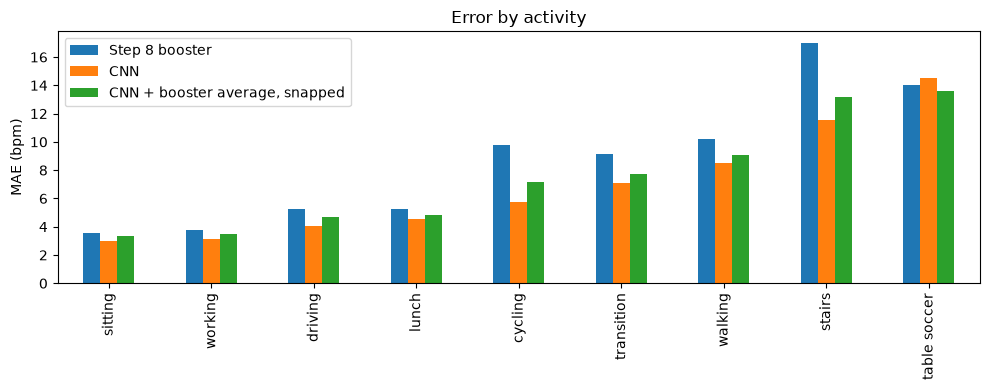

,CNN,"CNN, snapped",Step 8 booster,"CNN + booster average, snapped"
sitting,3.0,3.0,3.6,3.3
working,3.1,3.4,3.8,3.5
driving,4.1,4.5,5.3,4.7
lunch,4.6,4.9,5.2,4.9
cycling,5.7,5.7,9.8,7.2
transition,7.1,7.2,9.1,7.7
walking,8.5,8.6,10.2,9.0
stairs,11.6,11.5,17.0,13.2
table soccer,14.5,15.0,14.0,13.6


In [4]:
per_activity = pd.DataFrame({name: r["per_activity"] for name, r in summary.items()})
per_activity = per_activity.sort_values("CNN + booster average, snapped")
per_activity[["Step 8 booster", "CNN", "CNN + booster average, snapped"]].plot.bar(figsize=(10, 4))
plt.ylabel("MAE (bpm)")
plt.title("Error by activity")
plt.tight_layout()
plt.show()
per_activity.round(1)